# Scalable Algorithm Comparison

This notebook compares Greedy, Tree-aware heuristic, Uniform, and Random allocation-tree strategies on the expanded 1D and 2D benchmarks using surrogate final error. Exhaustive search is intentionally excluded because it is not practical for the larger $K$ and $M$ values.

Use the settings cell to switch between the deterministic test sample and the full expanded data set.


In [10]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Resolve paths whether the notebook is launched from the repository root or this folder.
working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
MODULE_DIRECTORY = PROJECT_DIRECTORY
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

# Reload algorithm code first so comparison_analysis sees the latest heuristic signature.
import heuristic
heuristic = importlib.reload(heuristic)

import approximate_comparison_analysis as comparison_analysis
comparison_analysis = importlib.reload(comparison_analysis)
approximate_summary = comparison_analysis.approximate_summary
field_family_summary = comparison_analysis.field_family_summary
load_approximate_results = comparison_analysis.load_approximate_results
overall_error_curve_summary = comparison_analysis.overall_error_curve_summary
runtime_by_k_summary = comparison_analysis.runtime_by_k_summary
run_approximate_dataset = comparison_analysis.run_approximate_dataset

print("Project directory:", PROJECT_DIRECTORY)
print("Source directory:", SOURCE_DIRECTORY)


Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential
Source directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/src


## Run Settings

Set `RUN_SCOPE = "test"` for the deterministic 100-case pilot sample or `RUN_SCOPE = "full"` for all 2,700 expanded cases per dimension. Both scopes use the same generated benchmark instances; the switch only changes how many saved cases are selected for evaluation.


In [11]:
# Run the expanded one-dimensional and two-dimensional datasets.
DATASETS = ["benchmark_1d", "benchmark_2d"]

# Switch here: "test" runs 100 balanced cases; "full" runs all 2,700 cases per dataset.
RUN_SCOPE = "full"
if RUN_SCOPE not in {"test", "full"}:
    raise ValueError('RUN_SCOPE must be "test" or "full"')

REPLICATES_PER_CELL = None
TEST_CASES_PER_DATASET = 100
CASE_LIMIT = None if RUN_SCOPE == "full" else TEST_CASES_PER_DATASET
CASE_SAMPLE_SEED = 20260820
PROGRESS_EVERY = 25

# Keep scalable results separate from the compact exact comparison.
RESULTS_ROOT = MODULE_DIRECTORY / "results" / "cmp_extended"

print("Run scope:", RUN_SCOPE)
print("Cases per dataset:", "2,700" if RUN_SCOPE == "full" else TEST_CASES_PER_DATASET)
print("Test-case sampling seed:", CASE_SAMPLE_SEED)
print("Results directory:", RESULTS_ROOT)


Run scope: full
Cases per dataset: 2,700
Test-case sampling seed: 20260820
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/cmp_extended


## Algorithm configuration



In [12]:
# Greedy has no optional tuning parameters.
GREEDY_PARAMETERS = {}

# Configure partial-tree beam search and allocation improvement.
HEURISTIC_PARAMETERS = {
    "beam_width": 3,
    "max_iterations": 5,
    "improvement_threshold": 1e-5,
    "initialization": "greedy",
    "move_shortlist_size": 1,
    "move_sizes": (1, 2, 3),
}

# Reproduce the near-uniform remainder placement.
UNIFORM_PARAMETERS = {"random_seed": 0}

# Reproduce case-specific random allocations and decision trees.
RANDOM_PARAMETERS = {"random_seed": 0}

print("Greedy parameters:", GREEDY_PARAMETERS)
print("Heuristic parameters:", HEURISTIC_PARAMETERS)
print("Uniform parameters:", UNIFORM_PARAMETERS)


Greedy parameters: {}
Heuristic parameters: {'beam_width': 3, 'max_iterations': 5, 'improvement_threshold': 1e-05, 'initialization': 'greedy', 'move_shortlist_size': 1, 'move_sizes': (1, 2, 3)}
Uniform parameters: {'random_seed': 0}


In [13]:
# Reload the runner so an open kernel cannot reuse an older case selector.
comparison_analysis = importlib.reload(comparison_analysis)
run_approximate_dataset = comparison_analysis.run_approximate_dataset

records_by_dataset = {}
for dataset in DATASETS:
    display(Markdown(f"### Running `{dataset}`"))
    records_by_dataset[dataset] = run_approximate_dataset(
        dataset,
        replicates_per_cell=REPLICATES_PER_CELL,
        results_root=RESULTS_ROOT,
        greedy_parameters=GREEDY_PARAMETERS,
        heuristic_parameters=HEURISTIC_PARAMETERS,
        uniform_parameters=UNIFORM_PARAMETERS,
        random_parameters=RANDOM_PARAMETERS,
        progress_every=PROGRESS_EVERY,
        case_limit=CASE_LIMIT,
        case_sample_seed=CASE_SAMPLE_SEED,
    )


### Running `benchmark_1d`

benchmark_1d: completed case 1/2700 (gaussian, K=3, M=3)
benchmark_1d: completed case 25/2700 (gaussian, K=3, M=3)
benchmark_1d: completed case 50/2700 (gaussian, K=3, M=4)
benchmark_1d: completed case 75/2700 (gaussian, K=3, M=5)
benchmark_1d: completed case 100/2700 (gaussian, K=3, M=6)
benchmark_1d: completed case 125/2700 (gaussian, K=3, M=7)
benchmark_1d: completed case 150/2700 (gaussian, K=3, M=7)
benchmark_1d: completed case 175/2700 (gaussian, K=3, M=8)
benchmark_1d: completed case 200/2700 (gaussian, K=4, M=3)
benchmark_1d: completed case 225/2700 (gaussian, K=4, M=4)
benchmark_1d: completed case 250/2700 (gaussian, K=4, M=5)
benchmark_1d: completed case 275/2700 (gaussian, K=4, M=6)
benchmark_1d: completed case 300/2700 (gaussian, K=4, M=6)
benchmark_1d: completed case 325/2700 (gaussian, K=4, M=7)
benchmark_1d: completed case 350/2700 (gaussian, K=4, M=8)
benchmark_1d: completed case 375/2700 (gaussian, K=5, M=3)
benchmark_1d: completed case 400/2700 (gaussian, K=5, M=4)
be

### Running `benchmark_2d`

benchmark_2d: completed case 1/2700 (gaussian, K=3, M=3)
benchmark_2d: completed case 25/2700 (gaussian, K=3, M=3)
benchmark_2d: completed case 50/2700 (gaussian, K=3, M=4)
benchmark_2d: completed case 75/2700 (gaussian, K=3, M=5)
benchmark_2d: completed case 100/2700 (gaussian, K=3, M=6)
benchmark_2d: completed case 125/2700 (gaussian, K=3, M=7)
benchmark_2d: completed case 150/2700 (gaussian, K=3, M=7)
benchmark_2d: completed case 175/2700 (gaussian, K=3, M=8)
benchmark_2d: completed case 200/2700 (gaussian, K=4, M=3)
benchmark_2d: completed case 225/2700 (gaussian, K=4, M=4)
benchmark_2d: completed case 250/2700 (gaussian, K=4, M=5)
benchmark_2d: completed case 275/2700 (gaussian, K=4, M=6)
benchmark_2d: completed case 300/2700 (gaussian, K=4, M=6)
benchmark_2d: completed case 325/2700 (gaussian, K=4, M=7)
benchmark_2d: completed case 350/2700 (gaussian, K=4, M=8)
benchmark_2d: completed case 375/2700 (gaussian, K=5, M=3)
benchmark_2d: completed case 400/2700 (gaussian, K=5, M=4)
be

## Numerical Summary

This table summarizes surrogate final error and runtime for each scalable method. It is a compact check on the full set of records used by the subsequent plots.


In [14]:
# Load saved records when the expensive run cell was intentionally skipped.
if "records_by_dataset" not in globals():
    records_by_dataset = {
        dataset: load_approximate_results(
            dataset, results_root=RESULTS_ROOT, run_scope=RUN_SCOPE
        )
        for dataset in DATASETS
    }

summary_lines = [
    "| Dataset | Algorithm | Cases | Budget runs | Mean surrogate error | Maximum surrogate error | Mean runtime (s) | Median runtime (s) |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for dataset, records in records_by_dataset.items():
    for row in approximate_summary(records):
        summary_lines.append(
            f"| {dataset} | {row['algorithm']} | {row['cases']} | {row['runs']} | "
            f"{row['mean_error']:.5f} | {row['maximum_error']:.5f} | "
            f"{row['mean_seconds']:.5f} | {row['median_seconds']:.5f} |"
        )

display(Markdown("\n".join(summary_lines)))


| Dataset | Algorithm | Cases | Budget runs | Mean surrogate error | Maximum surrogate error | Mean runtime (s) | Median runtime (s) |
|---|---|---:|---:|---:|---:|---:|---:|
| benchmark_1d | Greedy | 2700 | 10728 | 0.18594 | 0.78391 | 0.00887 | 0.00481 |
| benchmark_1d | Heuristic | 2700 | 10728 | 0.15582 | 0.71653 | 0.02990 | 0.01084 |
| benchmark_1d | Uniform | 2700 | 10728 | 0.45701 | 0.83552 | 0.00067 | 0.00055 |
| benchmark_1d | Random | 2700 | 10728 | 0.38942 | 0.80707 | 0.00066 | 0.00054 |
| benchmark_2d | Greedy | 2700 | 10732 | 0.21706 | 0.78370 | 0.00870 | 0.00481 |
| benchmark_2d | Heuristic | 2700 | 10732 | 0.18663 | 0.77300 | 0.02941 | 0.01064 |
| benchmark_2d | Uniform | 2700 | 10732 | 0.48227 | 0.84722 | 0.00066 | 0.00054 |
| benchmark_2d | Random | 2700 | 10732 | 0.42461 | 0.85475 | 0.00065 | 0.00053 |

## Overall Surrogate-Error Curve Summary

Each row matches one point in the overall mean surrogate-error curves. The final column reports the surrogate-error reduction achieved by the Tree-aware heuristic relative to Greedy; positive values mean the Tree-aware heuristic is better.


In [15]:
curve_summary_lines = [
    r"| Dimension | Budget level | Mean $N/N_{\min}^{opt}$ | Greedy mean surrogate error | Heuristic mean surrogate error | Uniform mean surrogate error | Random mean surrogate error | Heuristic reduction from Greedy |",
    "|---|---:|---:|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in overall_error_curve_summary(records):
        curve_summary_lines.append(
            f"| {row['dimension']} | {row['budget_level']} | "
            f"{row['mean_budget_fraction']:.3f} | "
            f"{row['greedy_mean_error']:.4f} | "
            f"{row['heuristic_mean_error']:.4f} | "
            f"{row['uniform_mean_error']:.4f} | "
            f"{row['random_mean_error']:.4f} | "
            f"{row['error_reduction']:.4f} "
            f"({row['error_reduction_percent']:.1f}%) |"
        )

display(Markdown("\n".join(summary_lines)))
display(Markdown("\n".join(curve_summary_lines)))


| Dataset | Algorithm | Cases | Budget runs | Mean surrogate error | Maximum surrogate error | Mean runtime (s) | Median runtime (s) |
|---|---|---:|---:|---:|---:|---:|---:|
| benchmark_1d | Greedy | 2700 | 10728 | 0.18594 | 0.78391 | 0.00887 | 0.00481 |
| benchmark_1d | Heuristic | 2700 | 10728 | 0.15582 | 0.71653 | 0.02990 | 0.01084 |
| benchmark_1d | Uniform | 2700 | 10728 | 0.45701 | 0.83552 | 0.00067 | 0.00055 |
| benchmark_1d | Random | 2700 | 10728 | 0.38942 | 0.80707 | 0.00066 | 0.00054 |
| benchmark_2d | Greedy | 2700 | 10732 | 0.21706 | 0.78370 | 0.00870 | 0.00481 |
| benchmark_2d | Heuristic | 2700 | 10732 | 0.18663 | 0.77300 | 0.02941 | 0.01064 |
| benchmark_2d | Uniform | 2700 | 10732 | 0.48227 | 0.84722 | 0.00066 | 0.00054 |
| benchmark_2d | Random | 2700 | 10732 | 0.42461 | 0.85475 | 0.00065 | 0.00053 |

| Dimension | Budget level | Mean $N/N_{\min}^{opt}$ | Greedy mean surrogate error | Heuristic mean surrogate error | Uniform mean surrogate error | Random mean surrogate error | Heuristic reduction from Greedy |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1D | 1 | 0.166 | 0.3685 | 0.3217 | 0.5941 | 0.5446 | 0.0469 (12.7%) |
| 1D | 2 | 0.315 | 0.1873 | 0.1575 | 0.5062 | 0.4201 | 0.0299 (15.9%) |
| 1D | 3 | 0.471 | 0.1096 | 0.0858 | 0.3976 | 0.3261 | 0.0237 (21.6%) |
| 1D | 4 | 0.602 | 0.0755 | 0.0557 | 0.3269 | 0.2638 | 0.0198 (26.2%) |
| 2D | 1 | 0.159 | 0.4061 | 0.3608 | 0.6098 | 0.5676 | 0.0453 (11.2%) |
| 2D | 2 | 0.297 | 0.2232 | 0.1921 | 0.5253 | 0.4576 | 0.0311 (13.9%) |
| 2D | 3 | 0.444 | 0.1375 | 0.1131 | 0.4301 | 0.3651 | 0.0244 (17.8%) |
| 2D | 4 | 0.564 | 0.0986 | 0.0778 | 0.3610 | 0.3052 | 0.0207 (21.0%) |

## Runtime summary by number of fields



In [16]:
runtime_summary_lines = [
    "| Dimension | $K$ | Greedy median runtime (s) | Heuristic median runtime (s) | Uniform median runtime (s) | Random median runtime (s) | Heuristic / Greedy runtime |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in runtime_by_k_summary(records):
        runtime_summary_lines.append(
            f"| {row['dimension']} | {row['K']} | "
            f"{row['greedy_median_seconds']:.6f} | "
            f"{row['heuristic_median_seconds']:.6f} | "
            f"{row['uniform_median_seconds']:.6f} | "
            f"{row['random_median_seconds']:.6f} | "
            f"{row['heuristic_to_greedy_ratio']:.2f}x |"
        )

display(Markdown("\n".join(summary_lines)))
display(Markdown("\n".join(runtime_summary_lines)))


| Dataset | Algorithm | Cases | Budget runs | Mean surrogate error | Maximum surrogate error | Mean runtime (s) | Median runtime (s) |
|---|---|---:|---:|---:|---:|---:|---:|
| benchmark_1d | Greedy | 2700 | 10728 | 0.18594 | 0.78391 | 0.00887 | 0.00481 |
| benchmark_1d | Heuristic | 2700 | 10728 | 0.15582 | 0.71653 | 0.02990 | 0.01084 |
| benchmark_1d | Uniform | 2700 | 10728 | 0.45701 | 0.83552 | 0.00067 | 0.00055 |
| benchmark_1d | Random | 2700 | 10728 | 0.38942 | 0.80707 | 0.00066 | 0.00054 |
| benchmark_2d | Greedy | 2700 | 10732 | 0.21706 | 0.78370 | 0.00870 | 0.00481 |
| benchmark_2d | Heuristic | 2700 | 10732 | 0.18663 | 0.77300 | 0.02941 | 0.01064 |
| benchmark_2d | Uniform | 2700 | 10732 | 0.48227 | 0.84722 | 0.00066 | 0.00054 |
| benchmark_2d | Random | 2700 | 10732 | 0.42461 | 0.85475 | 0.00065 | 0.00053 |

| Dimension | $K$ | Greedy median runtime (s) | Heuristic median runtime (s) | Uniform median runtime (s) | Random median runtime (s) | Heuristic / Greedy runtime |
|---|---:|---:|---:|---:|---:|---:|
| 1D | 3 | 0.000826 | 0.001355 | 0.000139 | 0.000137 | 1.63x |
| 1D | 4 | 0.002357 | 0.003973 | 0.000302 | 0.000298 | 1.75x |
| 1D | 5 | 0.004950 | 0.009893 | 0.000540 | 0.000534 | 2.00x |
| 1D | 6 | 0.009541 | 0.027074 | 0.000856 | 0.000848 | 2.83x |
| 1D | 7 | 0.018603 | 0.078622 | 0.001379 | 0.001340 | 4.72x |
| 2D | 3 | 0.000856 | 0.001355 | 0.000142 | 0.000141 | 1.60x |
| 2D | 4 | 0.002318 | 0.003765 | 0.000284 | 0.000280 | 1.73x |
| 2D | 5 | 0.004752 | 0.009848 | 0.000537 | 0.000531 | 2.04x |
| 2D | 6 | 0.009627 | 0.026397 | 0.000873 | 0.000858 | 2.81x |
| 2D | 7 | 0.018631 | 0.077237 | 0.001340 | 0.001320 | 4.73x |

## Surrogate-Error Summary by Field Family

Each row averages surrogate final error over all included $K$, $M$, sensor budgets, and replicates. The final column reports the Tree-aware heuristic's surrogate-error reduction relative to Greedy.


In [17]:
family_summary_lines = [
    "| Dimension | Field family | Greedy mean surrogate error | Heuristic mean surrogate error | Uniform mean surrogate error | Random mean surrogate error | Heuristic reduction from Greedy |",
    "|---|---|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in field_family_summary(records):
        family_summary_lines.append(
            f"| {row['dimension']} | {row['field_family']} | "
            f"{row['greedy_mean_error']:.4f} | "
            f"{row['heuristic_mean_error']:.4f} | "
            f"{row['uniform_mean_error']:.4f} | "
            f"{row['random_mean_error']:.4f} | "
            f"{row['heuristic_reduction']:.4f} "
            f"({row['heuristic_reduction_percent']:.1f}%) |"
        )

display(Markdown("\n".join(summary_lines)))
display(Markdown("\n".join(family_summary_lines)))


| Dataset | Algorithm | Cases | Budget runs | Mean surrogate error | Maximum surrogate error | Mean runtime (s) | Median runtime (s) |
|---|---|---:|---:|---:|---:|---:|---:|
| benchmark_1d | Greedy | 2700 | 10728 | 0.18594 | 0.78391 | 0.00887 | 0.00481 |
| benchmark_1d | Heuristic | 2700 | 10728 | 0.15582 | 0.71653 | 0.02990 | 0.01084 |
| benchmark_1d | Uniform | 2700 | 10728 | 0.45701 | 0.83552 | 0.00067 | 0.00055 |
| benchmark_1d | Random | 2700 | 10728 | 0.38942 | 0.80707 | 0.00066 | 0.00054 |
| benchmark_2d | Greedy | 2700 | 10732 | 0.21706 | 0.78370 | 0.00870 | 0.00481 |
| benchmark_2d | Heuristic | 2700 | 10732 | 0.18663 | 0.77300 | 0.02941 | 0.01064 |
| benchmark_2d | Uniform | 2700 | 10732 | 0.48227 | 0.84722 | 0.00066 | 0.00054 |
| benchmark_2d | Random | 2700 | 10732 | 0.42461 | 0.85475 | 0.00065 | 0.00053 |

| Dimension | Field family | Greedy mean surrogate error | Heuristic mean surrogate error | Uniform mean surrogate error | Random mean surrogate error | Heuristic reduction from Greedy |
|---|---|---:|---:|---:|---:|---:|
| 1D | gaussian | 0.1974 | 0.1623 | 0.4778 | 0.4128 | 0.0351 (17.8%) |
| 1D | sinusoidal | 0.1056 | 0.0852 | 0.3118 | 0.2605 | 0.0204 (19.3%) |
| 1D | quadratic | 0.2532 | 0.2185 | 0.5785 | 0.4925 | 0.0347 (13.7%) |
| 2D | gaussian | 0.2744 | 0.2390 | 0.5436 | 0.5048 | 0.0355 (12.9%) |
| 2D | sinusoidal | 0.1024 | 0.0839 | 0.3024 | 0.2568 | 0.0185 (18.1%) |
| 2D | quadratic | 0.2722 | 0.2351 | 0.5974 | 0.5090 | 0.0370 (13.6%) |

## Comparison Plots

These figures report surrogate final error because this notebook evaluates the optimization objective used by the algorithms.

The detailed mean-error figure retains separate panels for each $K$. A second summarized figure shows 1D and 2D panels averaged across all included $K$, $M$, and field families. The field-family figure uses vertical boxplots and the same muted algorithm colors. The heuristic-iteration figure shows the distribution of iterations performed before stopping, with the configured maximum shown by a dashed line.


### Mean surrogate-error curves

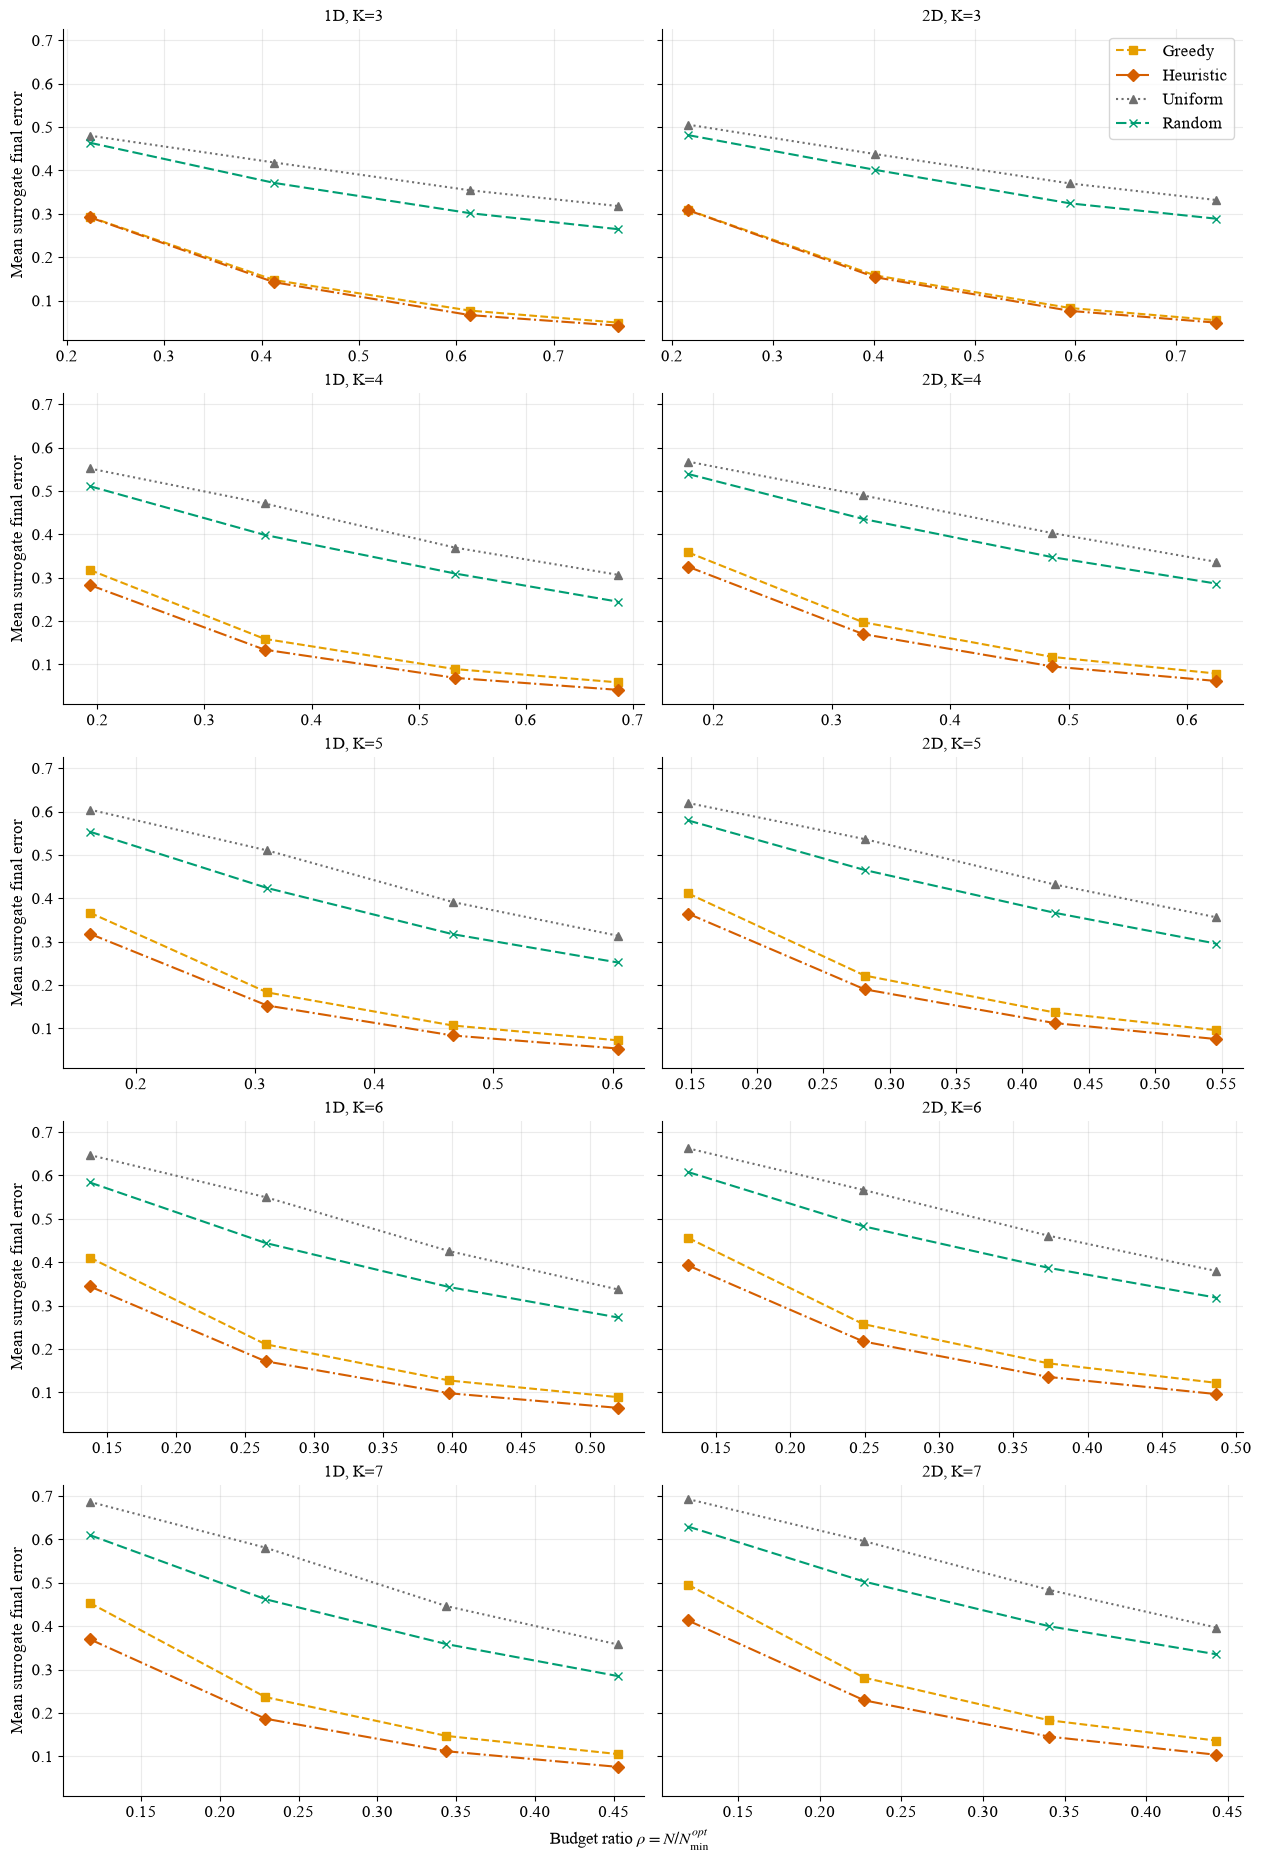

### Overall mean surrogate-error curves

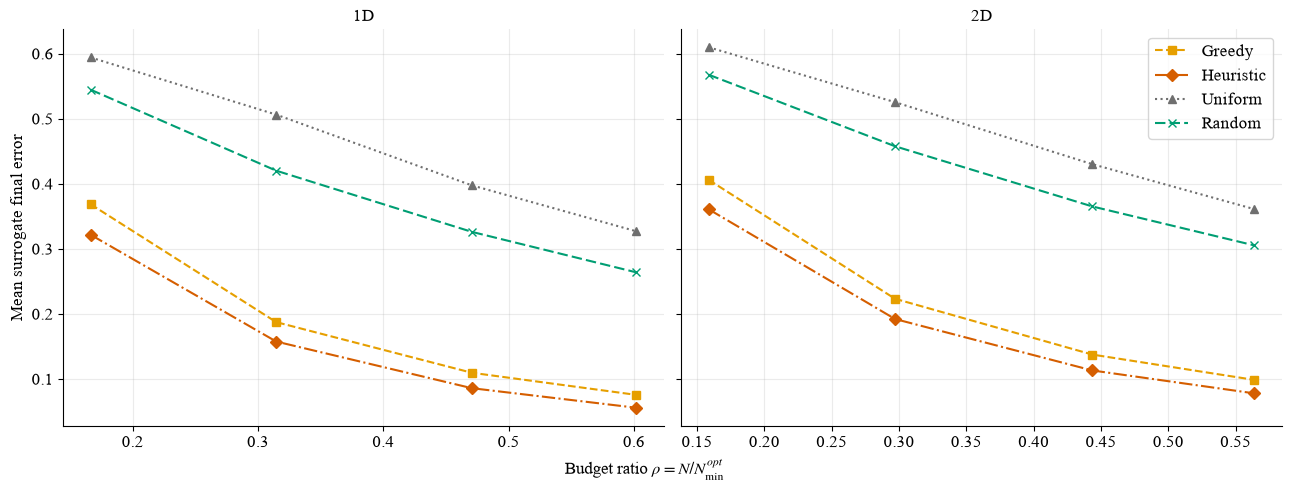

### Surrogate-error distribution by field family

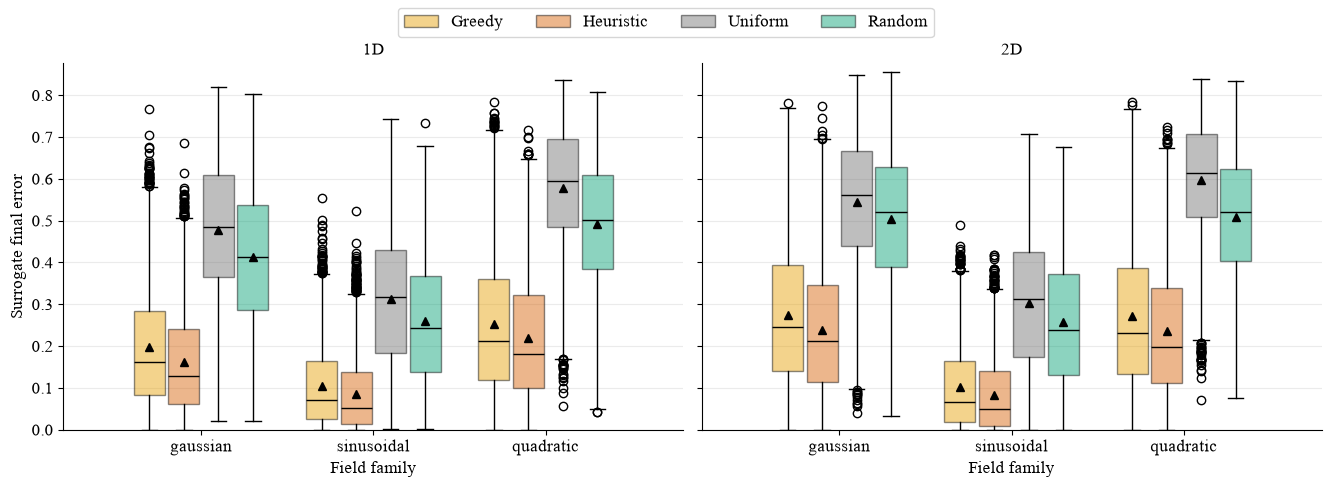

### Heuristic iteration distribution

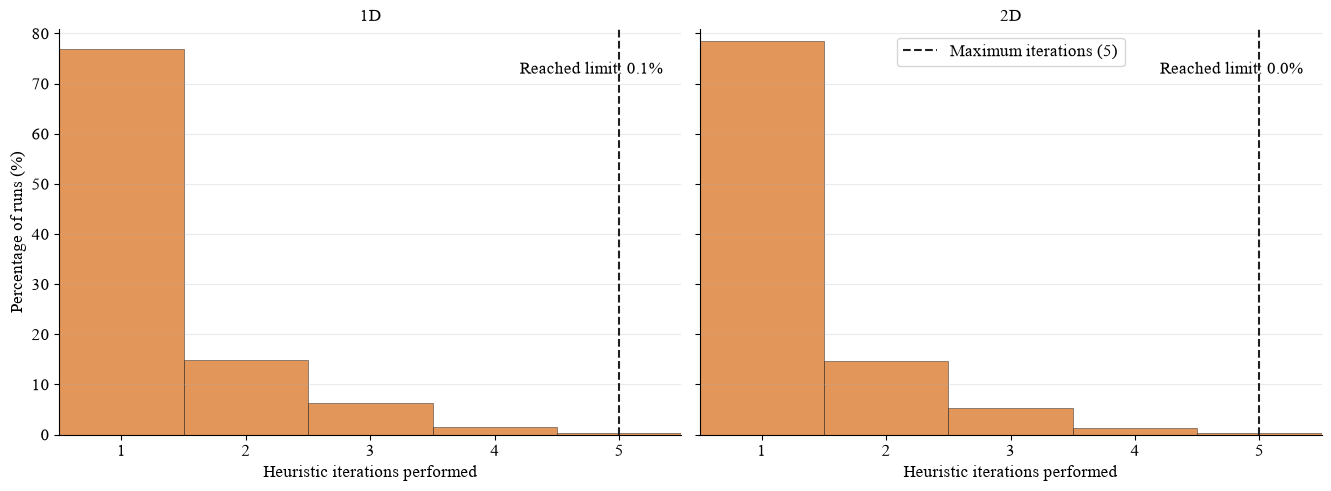

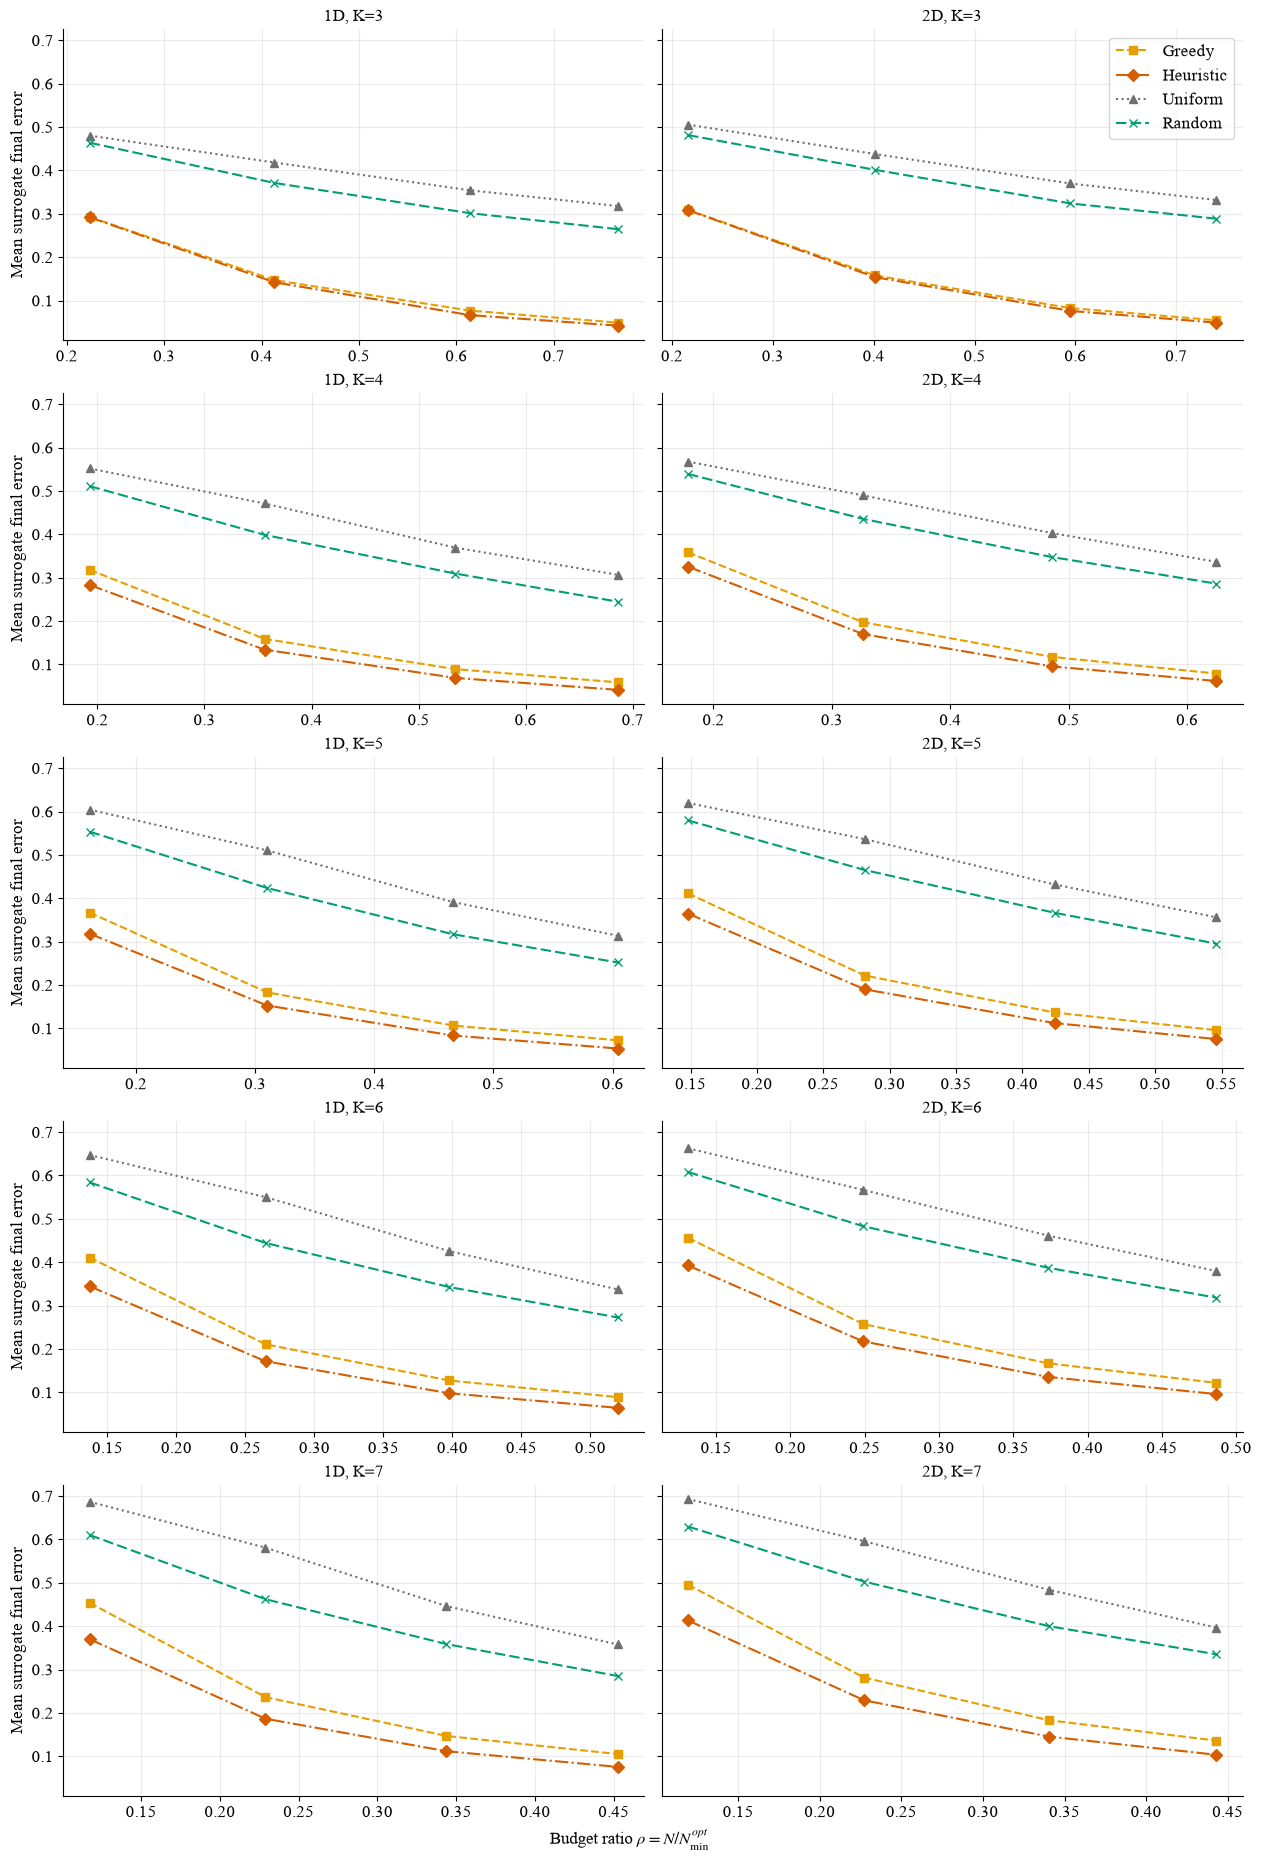

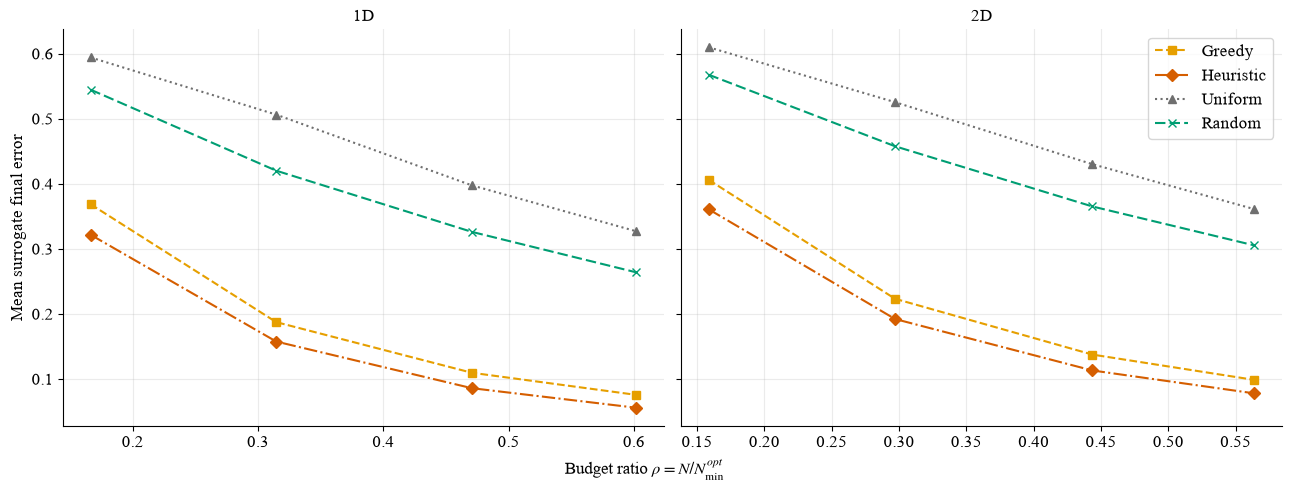

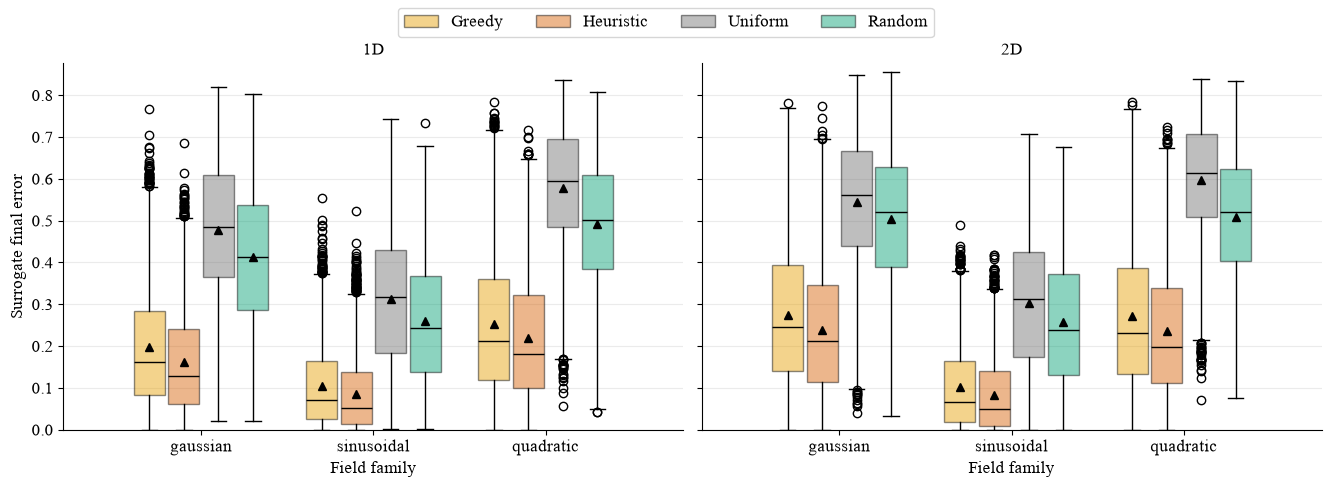

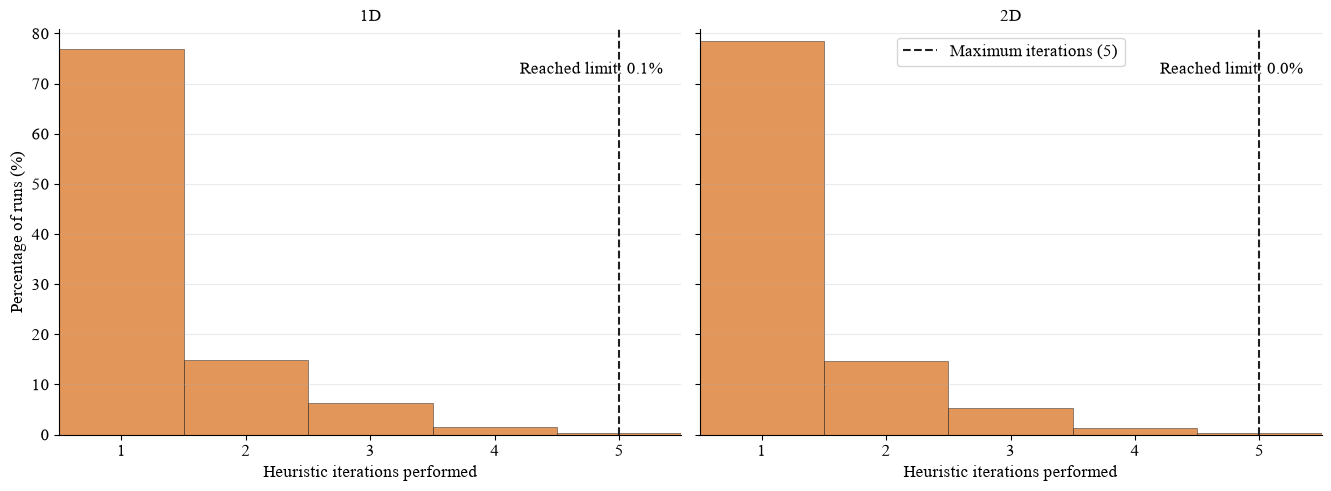

In [18]:
# Close figures left in memory by an earlier notebook run.
plt.close("all")

# Reload and apply the shared style before creating new figures.
import plot_style
plot_style = importlib.reload(plot_style)
plot_style.configure_plot_style()
# Reload plotting code so an open kernel does not reuse an older function.
comparison_analysis = importlib.reload(comparison_analysis)
# Load saved records when the expensive run cell was intentionally skipped.
if "records_by_dataset" not in globals():
    records_by_dataset = {
        dataset: comparison_analysis.load_approximate_results(
            dataset, results_root=RESULTS_ROOT, run_scope=RUN_SCOPE
        )
        for dataset in DATASETS
    }
figures = comparison_analysis.make_combined_approximate_plots(
    records_by_dataset,
    results_root=RESULTS_ROOT,
    run_scope=RUN_SCOPE,
)
for title, figure in figures:
    display(Markdown(f"### {title}"))
    display(figure)


## Saved files

```text
results/cmp_extended/
├── extended_1d_<test|full>/tables/
├── extended_2d_<test|full>/tables/
└── summary_extended_1d_extended_2d_<test|full>/figures/
